In [1]:
import numpy as np
import matplotlib.pyplot as plt
from keras.datasets import mnist
from itertools import combinations

np.random.seed(42)

In [2]:
def cumArray(img):
    img2 = img.copy()
    for i in range(1, img2.shape[0]):
        img2[i, :] += img2[i - 1, :]
    return img2 > 0


def getHolePixels(img):
    im1 = cumArray(img)
    im2 = np.rot90(cumArray(np.rot90(img)), 3)
    im3 = np.rot90(cumArray(np.rot90(img, 2)), 2)
    im4 = np.rot90(cumArray(np.rot90(img, 3)), 1)
    hull = im1 & im2 & im3 & im4
    return hull & ~(img > 0)


def getHullPixels(img):
    im1 = cumArray(img)
    im2 = np.rot90(cumArray(np.rot90(img)), 3)
    im3 = np.rot90(cumArray(np.rot90(img, 2)), 2)
    im4 = np.rot90(cumArray(np.rot90(img, 3)), 1)
    return im1 & im2 & im3 & im4


def getBoundaryPixels(img):
    img = img.copy() > 0
    rshift = np.roll(img, 1, axis=1)
    lshift = np.roll(img, -1, axis=1)
    ushift = np.roll(img, -1, axis=0)
    dshift = np.roll(img, 1, axis=0)

    return (
        (img & ~rshift) |
        (img & ~lshift) |
        (img & ~ushift) |
        (img & ~dshift)
    )


def NN(train_data, train_labels, test_data):
    predictions = []

    for query in test_data:
        distances = np.sum((train_data - query) ** 2, axis=1)
        predictions.append(train_labels[np.argmin(distances)])

    return np.array(predictions)


def Accuracy(actual, predicted):
    return np.mean(actual == predicted)

In [3]:
(train_X, train_y), (test_X, test_y) = mnist.load_data()

train_X = train_X / 255.0
test_X = test_X / 255.0

# Select the first four classes: digits 0, 1, 2 and 3
train_mask = train_y < 4
test_mask = test_y < 4

train_X = train_X[train_mask][::100].copy()
train_y = train_y[train_mask][::100].copy()

test_X = test_X[test_mask][::100].copy()
test_y = test_y[test_mask][::100].copy()

print("Training samples:", len(train_X))
print("Testing samples:", len(test_X))
print("Classes:", np.unique(train_y))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 248
Testing samples: 42
Classes: [0 1 2 3]


In [4]:
def extract_features(images):
    holes = np.array([getHolePixels(img).sum() for img in images])
    boundaries = np.array([getBoundaryPixels(img).sum() for img in images])
    hulls = np.array([getHullPixels(img).sum() for img in images])
    pixel_sums = np.sum(images, axis=(1, 2))

    return np.column_stack((holes, boundaries, hulls, pixel_sums))


train_features = extract_features(train_X)
test_features = extract_features(test_X)

feature_names = ["Hole Pixels", "Boundary Pixels",
                 "Hull Pixels", "Pixel Intensity Sum"]

print("Feature names:", feature_names)
print("Training feature shape:", train_features.shape)
print("Testing feature shape:", test_features.shape)

Feature names: ['Hole Pixels', 'Boundary Pixels', 'Hull Pixels', 'Pixel Intensity Sum']
Training feature shape: (248, 4)
Testing feature shape: (42, 4)


In [5]:
# Original two features: hole pixels and boundary pixels
train_feats = train_features[:, :2]
test_feats = test_features[:, :2]

baseline_pred = NN(train_feats, train_y, test_feats)
baseline_acc = Accuracy(test_y, baseline_pred) * 100

print("Baseline accuracy:", round(baseline_acc, 2), "%")

Baseline accuracy: 76.19 %


Original accuracy: 76.19 %
Lab Matrix accuracy: 80.95 %
Scale X accuracy: 76.19 %
Scale Y accuracy: 78.57 %
Shear accuracy: 73.81 %
Rotate-like accuracy: 76.19 %

Best transformation: Lab Matrix
Best accuracy: 80.95 %


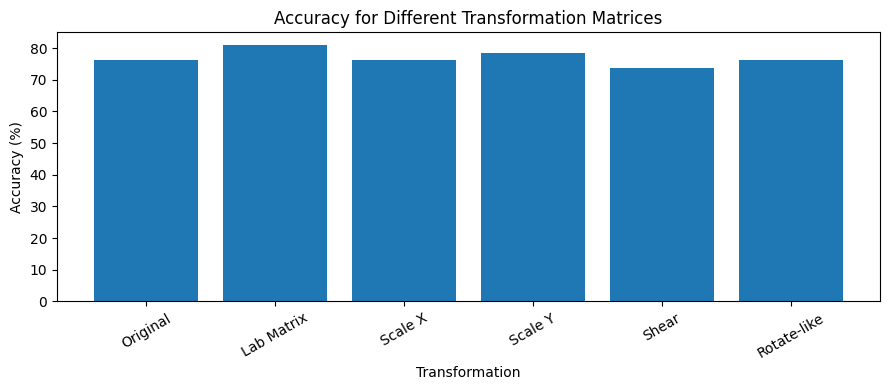

In [6]:
transforms = {
    "Original": np.array([[1, 0], [0, 1]]),
    "Lab Matrix": np.array([[0.5, -0.5], [0, 2.5]]),
    "Scale X": np.array([[2, 0], [0, 0.5]]),
    "Scale Y": np.array([[0.5, 0], [0, 2]]),
    "Shear": np.array([[1, 0.5], [0, 1]]),
    "Rotate-like": np.array([[0, -1], [1, 0]])
}

transform_results = {}

for name, matrix in transforms.items():
    X_train_t = train_feats @ matrix
    X_test_t = test_feats @ matrix

    pred = NN(X_train_t, train_y, X_test_t)
    acc = Accuracy(test_y, pred) * 100

    transform_results[name] = acc
    print(name, "accuracy:", round(acc, 2), "%")

best_transform = max(transform_results, key=transform_results.get)

print("\nBest transformation:", best_transform)
print("Best accuracy:", round(transform_results[best_transform], 2), "%")

plt.figure(figsize=(9, 4))
plt.bar(transform_results.keys(), transform_results.values())
plt.ylabel("Accuracy (%)")
plt.xlabel("Transformation")
plt.title("Accuracy for Different Transformation Matrices")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Hole Pixels + Boundary Pixels accuracy: 80.95 %
Hole Pixels + Hull Pixels accuracy: 71.43 %
Hole Pixels + Pixel Intensity Sum accuracy: 59.52 %
Boundary Pixels + Hull Pixels accuracy: 69.05 %
Boundary Pixels + Pixel Intensity Sum accuracy: 59.52 %
Hull Pixels + Pixel Intensity Sum accuracy: 59.52 %


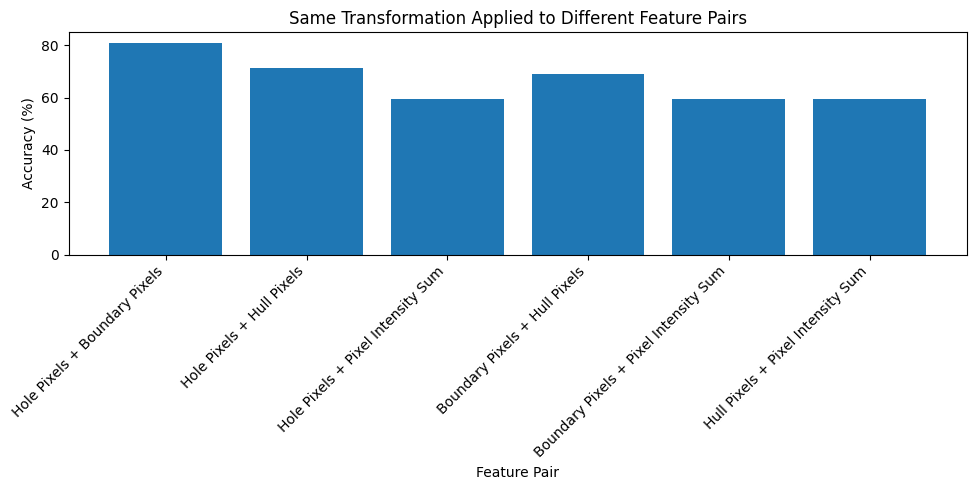

In [7]:
feature_pairs = list(combinations(range(4), 2))

matrix = np.array([[0.5, -0.5],
                   [0, 2.5]])

pair_results = {}

for i, j in feature_pairs:
    X_train_pair = train_features[:, [i, j]]
    X_test_pair = test_features[:, [i, j]]

    X_train_t = X_train_pair @ matrix
    X_test_t = X_test_pair @ matrix

    pred = NN(X_train_t, train_y, X_test_t)
    acc = Accuracy(test_y, pred) * 100

    pair_name = feature_names[i] + " + " + feature_names[j]
    pair_results[pair_name] = acc

    print(pair_name, "accuracy:", round(acc, 2), "%")

plt.figure(figsize=(10, 5))
plt.bar(pair_results.keys(), pair_results.values())
plt.ylabel("Accuracy (%)")
plt.xlabel("Feature Pair")
plt.title("Same Transformation Applied to Different Feature Pairs")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Hole Pixels + Boundary Pixels accuracy: 76.19 %
Hole Pixels + Hull Pixels accuracy: 73.81 %
Hole Pixels + Pixel Intensity Sum accuracy: 59.52 %
Boundary Pixels + Hull Pixels accuracy: 69.05 %
Boundary Pixels + Pixel Intensity Sum accuracy: 66.67 %
Hull Pixels + Pixel Intensity Sum accuracy: 71.43 %

Best feature combination: Hole Pixels + Boundary Pixels
Best accuracy: 76.19 %


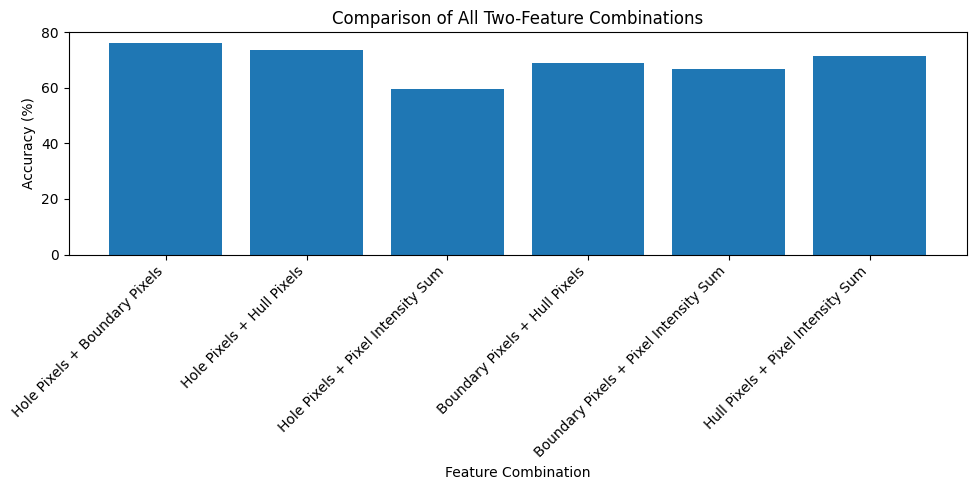

In [8]:
combination_results = {}

for i, j in combinations(range(4), 2):
    X_train_pair = train_features[:, [i, j]]
    X_test_pair = test_features[:, [i, j]]

    pred = NN(X_train_pair, train_y, X_test_pair)
    acc = Accuracy(test_y, pred) * 100

    pair_name = feature_names[i] + " + " + feature_names[j]
    combination_results[pair_name] = acc

    print(pair_name, "accuracy:", round(acc, 2), "%")

best_pair = max(combination_results, key=combination_results.get)

print("\nBest feature combination:", best_pair)
print("Best accuracy:", round(combination_results[best_pair], 2), "%")

plt.figure(figsize=(10, 5))
plt.bar(combination_results.keys(), combination_results.values())
plt.ylabel("Accuracy (%)")
plt.xlabel("Feature Combination")
plt.title("Comparison of All Two-Feature Combinations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [9]:
def fit_rescale(train_data, test_data):
    minimum = train_data.min(axis=0)
    maximum = train_data.max(axis=0)

    scale = maximum - minimum
    scale[scale == 0] = 1

    train_scaled = (train_data - minimum) / scale
    test_scaled = (test_data - minimum) / scale

    return train_scaled, test_scaled


train_scaled, test_scaled = fit_rescale(
    train_feats, test_feats
)

print("Minimum scaled training values:", train_scaled.min(axis=0))
print("Maximum scaled training values:", train_scaled.max(axis=0))

pred_scaled = NN(train_scaled, train_y, test_scaled)
scaled_acc = Accuracy(test_y, pred_scaled) * 100

print("Accuracy after normalization:", round(scaled_acc, 2), "%")
print("Baseline accuracy:", round(baseline_acc, 2), "%")
print("Change in accuracy:", round(scaled_acc - baseline_acc, 2),
      "percentage points")

Minimum scaled training values: [0. 0.]
Maximum scaled training values: [1. 1.]
Accuracy after normalization: 80.95 %
Baseline accuracy: 76.19 %
Change in accuracy: 4.76 percentage points


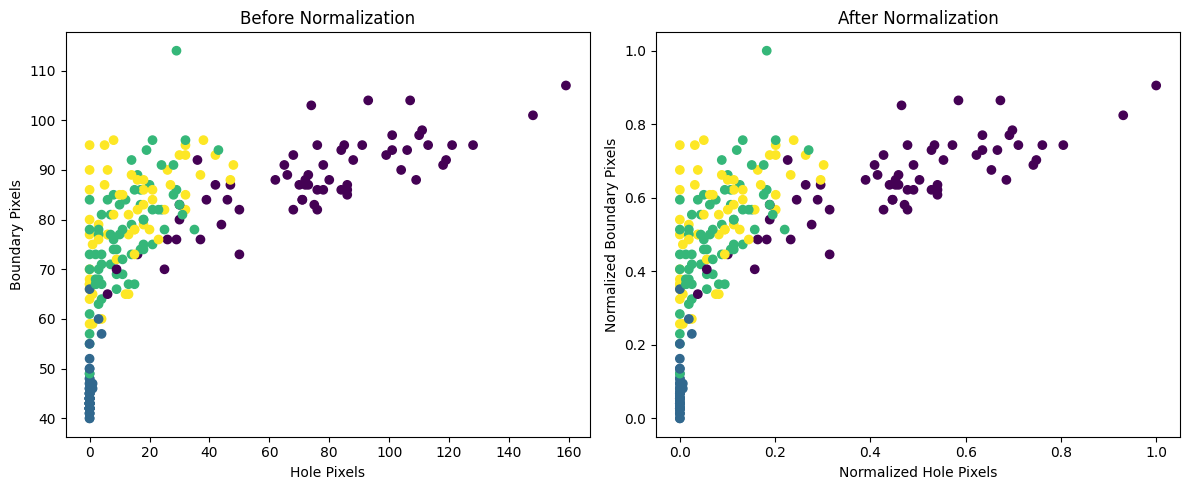

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(train_feats[:, 0], train_feats[:, 1], c=train_y)
axes[0].set_title("Before Normalization")
axes[0].set_xlabel("Hole Pixels")
axes[0].set_ylabel("Boundary Pixels")

axes[1].scatter(train_scaled[:, 0], train_scaled[:, 1], c=train_y)
axes[1].set_title("After Normalization")
axes[1].set_xlabel("Normalized Hole Pixels")
axes[1].set_ylabel("Normalized Boundary Pixels")

plt.tight_layout()
plt.show()

In [11]:
print("ASSIGNMENT SUMMARY")
print("=" * 40)

print("\n1. Baseline accuracy:",
      round(baseline_acc, 2), "%")

print("\n2. Best transformation:")
print(best_transform)
print("Accuracy:", round(transform_results[best_transform], 2), "%")

print("\n3. Best transformed feature pair:")
best_transformed_pair = max(pair_results, key=pair_results.get)
print(best_transformed_pair)
print("Accuracy:", round(pair_results[best_transformed_pair], 2), "%")

print("\n4. Best original feature combination:")
print(best_pair)
print("Accuracy:", round(combination_results[best_pair], 2), "%")

print("\n5. Accuracy after normalization:",
      round(scaled_acc, 2), "%")

ASSIGNMENT SUMMARY

1. Baseline accuracy: 76.19 %

2. Best transformation:
Lab Matrix
Accuracy: 80.95 %

3. Best transformed feature pair:
Hole Pixels + Boundary Pixels
Accuracy: 80.95 %

4. Best original feature combination:
Hole Pixels + Boundary Pixels
Accuracy: 76.19 %

5. Accuracy after normalization: 80.95 %


Question 1: Experiment with different transformation matrices and check the accuracy.
Different transformation matrices change the distances between data points. Since the nearest-neighbour algorithm uses distances to make predictions, the accuracy can change depending on the matrix. The best matrix is the one that produces the highest accuracy in the experiment.

Question 2: Will the same transform used for these two features also work for other features?
No, not necessarily. Different features have different scales and distributions. A transformation that improves accuracy for hole pixels and boundary pixels may not work equally well for hull pixels and total pixel intensity. Each feature combination should be evaluated separately.

Exercise:
Is adding all four features always the best strategy?
No. Additional features do not necessarily improve classification accuracy. Some features may provide redundant or less useful information. Comparing pairs of features helps identify which combinations distinguish the digit classes most effectively.

Data normalization: Why is it useful?
Normalization brings features to a comparable scale, preventing features with larger numerical values from dominating distance calculations. Min-max rescaling maps training feature values to the range 0–1 and applies the same training-derived scaling parameters to the test set.